In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

df = pd.read_parquet('../data/processed/yellow_tripdata_2024-01_engineered.parquet')
zones = pd.read_csv('../data/raw/taxi_zone_lookup.csv')
print(f"Loaded: {len(df):,} rows")

Loaded: 2,338,354 rows


In [2]:
# ============================================
# ZONE-HOUR AGGREGATION (Core Analytical Table)
# ============================================
zone_hour = df.groupby(['PU_borough','PU_zone','PULocationID',
                         'pickup_hour','day_type','peak_period']).agg(
    trip_count=('trip_distance','count'),
    total_passengers=('passenger_count','sum'),
    avg_distance=('trip_distance','mean'),
    avg_duration=('trip_duration_min','mean'),
    avg_speed=('avg_speed_mph','mean'),
    avg_fare=('fare_amount','mean'),
    avg_fare_per_mile=('fare_per_mile','mean'),
    pct_congested=('is_congested_trip','mean'),
    avg_congestion_severity=('congestion_severity','mean')
).reset_index()

zone_hour = zone_hour.round(2)
print(f"Zone-Hour aggregation: {zone_hour.shape[0]:,} rows x {zone_hour.shape[1]} cols")
zone_hour.head()

Zone-Hour aggregation: 7,215 rows x 15 cols


,PU_borough,PU_zone,PULocationID,pickup_hour,day_type,peak_period,trip_count,total_passengers,avg_distance,avg_duration,avg_speed,avg_fare,avg_fare_per_mile,pct_congested,avg_congestion_severity
0,Bronx,Allerton/Pelham Gardens,3,6,Weekend,Early Morning,1,1.0,3.11,15.27,12.22,21.27,6.84,0.00,3.00
1,Bronx,Allerton/Pelham Gardens,3,8,Weekday,Morning Peak,1,1.0,1.40,14.82,5.67,20.50,14.64,1.00,5.00
2,Bronx,Allerton/Pelham Gardens,3,8,Weekend,Morning Peak,1,1.0,0.20,2.45,4.90,19.50,NaN,1.00,5.00
3,Bronx,Allerton/Pelham Gardens,3,10,Weekday,Off-Peak,3,4.0,1.97,12.57,8.38,18.40,14.43,0.67,4.33
4,Bronx,Allerton/Pelham Gardens,3,12,Weekend,Midday,1,1.0,3.70,19.33,11.48,21.50,5.81,0.00,4.00


In [3]:
# ============================================
# ROUTE-LEVEL AGGREGATION
# ============================================
route_stats = df.groupby(['PULocationID','DOLocationID',
                           'PU_zone','DO_zone','PU_borough']).agg(
    trip_count=('trip_distance','count'),
    avg_distance=('trip_distance','mean'),
    avg_duration=('trip_duration_min','mean'),
    avg_speed=('avg_speed_mph','mean'),
    avg_fare=('fare_amount','mean'),
    pct_congested=('is_congested_trip','mean'),
    avg_congestion_severity=('congestion_severity','mean')
).reset_index()

route_stats = route_stats.round(2)
route_stats = route_stats.sort_values('trip_count', ascending=False)
print(f"Route aggregation: {route_stats.shape[0]:,} unique routes")
print(f"\nTop 10 busiest routes:")
print(route_stats.head(10)[['PU_zone','DO_zone','trip_count','avg_speed','avg_duration']].to_string())

Route aggregation: 9,190 unique routes

Top 10 busiest routes:
                    PU_zone                DO_zone  trip_count  avg_speed  avg_duration
8115  Upper East Side South  Upper East Side North       21356       9.59          7.36
8027  Upper East Side North  Upper East Side South       18904       8.61          7.94
8026  Upper East Side North  Upper East Side North       14882       8.86          4.63
8116  Upper East Side South  Upper East Side South       13800       7.81          5.58
5443         Midtown Center  Upper East Side South        9996       7.95          9.08
4598    Lincoln Square East  Upper West Side South        8707      10.20          6.16
8089  Upper East Side South         Midtown Center        8574       7.96          8.82
8230  Upper West Side South    Lincoln Square East        8421       9.42          6.10
5442         Midtown Center  Upper East Side North        8416      10.02         12.89
8265  Upper West Side South  Upper West Side North       

In [4]:
# ============================================
# CONGESTION CLASSIFICATION
# ============================================
def classify_congestion(row):
    speed = row['avg_speed']
    pct = row['pct_congested']
    if pd.isna(speed):
        return 'Unknown'
    if speed < 8 and pct > 0.6:
        return 'Severe'
    elif speed < 12 and pct > 0.4:
        return 'Heavy'
    elif speed < 18 and pct > 0.25:
        return 'Moderate'
    elif speed < 25 and pct > 0.1:
        return 'Light'
    else:
        return 'Free Flow'

zone_hour['congestion_class'] = zone_hour.apply(classify_congestion, axis=1)

print("Congestion Classification Distribution:")
print(zone_hour['congestion_class'].value_counts())

Congestion Classification Distribution:
congestion_class
Heavy        2325
Free Flow    1835
Moderate     1143
Severe       1016
Light         889
Unknown         7
Name: count, dtype: int64


In [5]:
# ============================================
# ROUTE EFFICIENCY SCORE
# ============================================
route_valid = route_stats.dropna(subset=['avg_speed','avg_fare']).copy()
route_valid = route_valid[route_valid['avg_speed'] > 0]

scaler_speed = MinMaxScaler()
route_valid['speed_norm'] = scaler_speed.fit_transform(route_valid[['avg_speed']])

scaler_dur = MinMaxScaler()
route_valid['duration_norm'] = scaler_dur.fit_transform(route_valid[['avg_duration']])
route_valid['duration_inv'] = 1 - route_valid['duration_norm']

route_valid['route_efficiency_score'] = (
    0.6 * route_valid['speed_norm'] +
    0.4 * route_valid['duration_inv']
) * 100

route_valid['route_efficiency_score'] = route_valid['route_efficiency_score'].round(1)

def efficiency_label(score):
    if score >= 75: return 'High'
    elif score >= 50: return 'Medium'
    elif score >= 25: return 'Low'
    else: return 'Very Low'

route_valid['efficiency_label'] = route_valid['route_efficiency_score'].apply(efficiency_label)

print("Route Efficiency Distribution:")
print(route_valid['efficiency_label'].value_counts())
print(f"\nMost Efficient Routes:")
print(route_valid.nlargest(5,'route_efficiency_score')[
    ['PU_zone','DO_zone','trip_count','avg_speed','route_efficiency_score']].to_string())
print(f"\nLeast Efficient Routes:")
print(route_valid.nsmallest(5,'route_efficiency_score')[
    ['PU_zone','DO_zone','trip_count','avg_speed','route_efficiency_score']].to_string())

Route Efficiency Distribution:
efficiency_label
Low         6037
Very Low    2840
Medium       262
High          48
Name: count, dtype: int64

Most Efficient Routes:
                             PU_zone                          DO_zone  trip_count  avg_speed  route_efficiency_score
6764    Schuylerville/Edgewater Park                  Pelham Bay Park           1      59.47                    95.8
7094       Springfield Gardens South                     Howard Beach           1      57.29                    94.0
341          Bay Terrace/Fort Totten                          Bayside           1      54.64                    92.6
464                 Bensonhurst East  Marine Park/Floyd Bennett Field           2      57.86                    91.9
4803  Long Island City/Hunters Point                      Kew Gardens           1      57.38                    91.8

Least Efficient Routes:
                  PU_zone              DO_zone  trip_count  avg_speed  route_efficiency_score
5881         

In [6]:
# ============================================
# ★★★ MOBILITY PRIORITY SCORE ★★★
# High Demand + High Congestion + Low Speed + Long Duration
# ============================================
zone_hour_valid = zone_hour.dropna(subset=['avg_speed']).copy()
zone_hour_valid = zone_hour_valid[zone_hour_valid['avg_speed'] > 0]

scaler = MinMaxScaler()

zone_hour_valid['demand_norm'] = scaler.fit_transform(
    zone_hour_valid[['trip_count']]
)
zone_hour_valid['congestion_norm'] = scaler.fit_transform(
    zone_hour_valid[['avg_congestion_severity']]
)
zone_hour_valid['speed_inv_norm'] = scaler.fit_transform(
    (1 / zone_hour_valid[['avg_speed']]).values.reshape(-1,1)
)
zone_hour_valid['duration_norm'] = scaler.fit_transform(
    zone_hour_valid[['avg_duration']]
)

# Weights: Demand=30%, Congestion=30%, Speed_Inv=20%, Duration=20%
zone_hour_valid['mobility_priority_score'] = (
    0.30 * zone_hour_valid['demand_norm'] +
    0.30 * zone_hour_valid['congestion_norm'] +
    0.20 * zone_hour_valid['speed_inv_norm'] +
    0.20 * zone_hour_valid['duration_norm']
) * 100

zone_hour_valid['mobility_priority_score'] = zone_hour_valid['mobility_priority_score'].round(1)

def priority_label(score):
    if score >= 75: return 'Critical'
    elif score >= 55: return 'High'
    elif score >= 35: return 'Medium'
    elif score >= 15: return 'Low'
    else: return 'Minimal'

zone_hour_valid['priority_label'] = zone_hour_valid['mobility_priority_score'].apply(priority_label)

print("★ MOBILITY PRIORITY SCORE DISTRIBUTION:")
print(zone_hour_valid['priority_label'].value_counts())
print(f"\n🔴 TOP 10 CRITICAL MOBILITY HOTSPOTS:")
critical = zone_hour_valid.nlargest(10, 'mobility_priority_score')
print(critical[['PU_zone','pickup_hour','day_type','trip_count',
                'avg_speed','avg_duration','mobility_priority_score',
                'priority_label']].to_string())

★ MOBILITY PRIORITY SCORE DISTRIBUTION:
priority_label
Low        5159
Medium     1714
Minimal     322
High         13
Name: count, dtype: int64

🔴 TOP 10 CRITICAL MOBILITY HOTSPOTS:
                    PU_zone  pickup_hour day_type  trip_count  avg_speed  avg_duration  mobility_priority_score priority_label
299     Kingsbridge Heights           11  Weekend           1       0.24         25.32                     68.5           High
4251         Midtown Center           18  Weekday       10890       7.79         12.44                     64.7           High
4249         Midtown Center           17  Weekday        9742       7.07         13.19                     63.3           High
5107  Upper East Side South           14  Weekday        8614       7.25         11.05                     58.4           High
4253         Midtown Center           19  Weekday        9339       8.86         11.64                     58.1           High
5061  Upper East Side North           15  Weekday      

In [7]:
# ============================================
# ZONE-LEVEL PRIORITY AGGREGATION (for Tableau map)
# ============================================
zone_priority = zone_hour_valid.groupby(['PULocationID','PU_zone','PU_borough']).agg(
    total_trips=('trip_count','sum'),
    avg_speed=('avg_speed','mean'),
    avg_duration=('avg_duration','mean'),
    avg_congestion=('avg_congestion_severity','mean'),
    max_priority_score=('mobility_priority_score','max'),
    avg_priority_score=('mobility_priority_score','mean'),
    critical_hours=('priority_label', lambda x: (x=='Critical').sum()),
    high_hours=('priority_label', lambda x: (x=='High').sum())
).reset_index()

zone_priority = zone_priority.round(2)
zone_priority = zone_priority.sort_values('avg_priority_score', ascending=False)

print("★ Top 15 Priority Zones:")
print(zone_priority.head(15)[['PU_zone','PU_borough','total_trips',
    'avg_speed','avg_priority_score','critical_hours','high_hours']].to_string())

★ Top 15 Priority Zones:
                          PU_zone PU_borough  total_trips  avg_speed  avg_priority_score  critical_hours  high_hours
31                    Brownsville   Brooklyn          141       7.58               38.37               0           0
146                Midtown Center  Manhattan       125288      10.07               37.15               0           6
87                  Fordham South      Bronx           29       8.91               36.91               0           0
78                        Erasmus   Brooklyn           65       8.77               36.76               0           0
169  Penn Station/Madison Sq West  Manhattan        89038       9.66               36.59               0           0
98                      Gravesend   Brooklyn           11       7.95               36.51               0           0
66   East Flatbush/Remsen Village   Brooklyn          129       8.77               35.50               0           0
23                   Borough Park   Bro

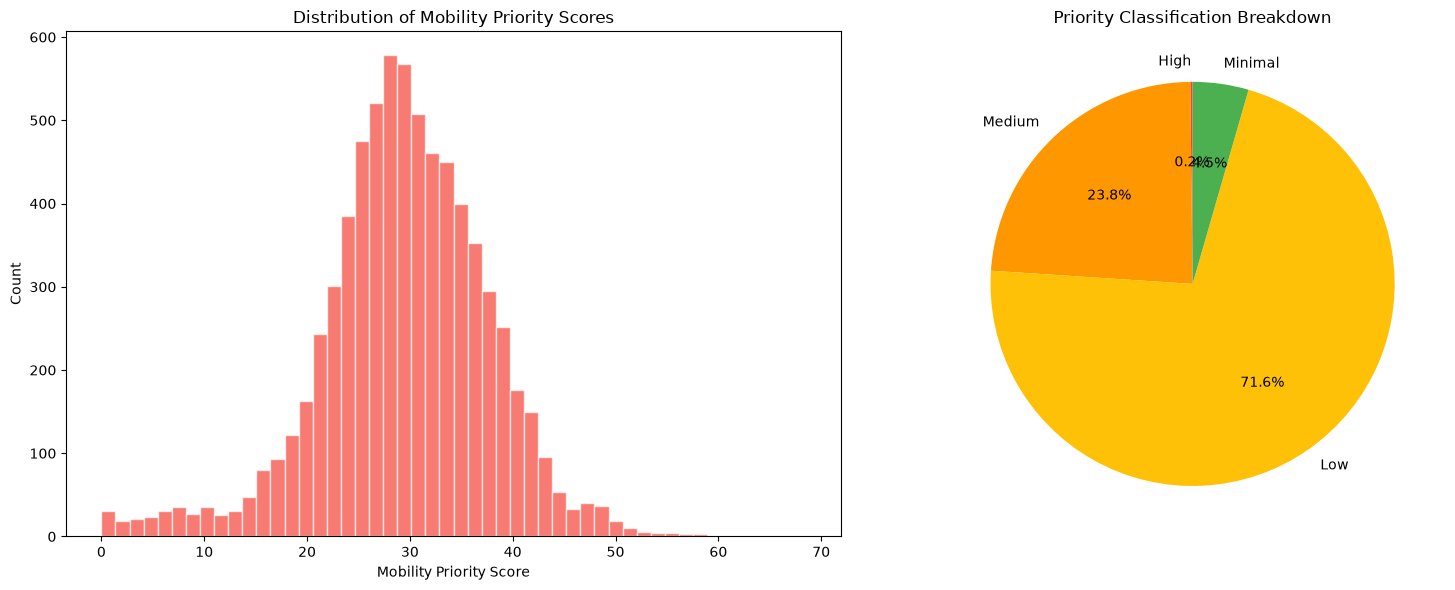

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].hist(zone_hour_valid['mobility_priority_score'], bins=50,
             color='#F44336', alpha=0.7, edgecolor='white')
axes[0].set_xlabel('Mobility Priority Score')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Mobility Priority Scores')

priority_counts = zone_hour_valid['priority_label'].value_counts()
priority_order = ['Critical','High','Medium','Low','Minimal']
priority_counts = priority_counts.reindex(priority_order).dropna()
colors_pie = ['#F44336','#FF9800','#FFC107','#4CAF50','#2196F3']
axes[1].pie(priority_counts, labels=priority_counts.index,
            colors=colors_pie[:len(priority_counts)], autopct='%1.1f%%', startangle=90)
axes[1].set_title('Priority Classification Breakdown')

plt.tight_layout()
plt.savefig('../visuals/07_priority_analysis.png', dpi=150)
plt.show()

In [9]:
import os
os.makedirs('../data/processed', exist_ok=True)

# Save zone-hour with priority scores
zone_hour_valid.to_csv('../data/processed/tableau_zone_hour.csv', index=False)

# Save route stats with efficiency
route_valid.to_csv('../data/processed/tableau_routes.csv', index=False)

# Save zone priority
zone_priority.to_csv('../data/processed/tableau_zone_summary.csv', index=False)

# Save daily trend
daily = df.groupby('pickup_date').agg(
    daily_trips=('trip_distance','count'),
    avg_speed=('avg_speed_mph','mean'),
    avg_duration=('trip_duration_min','mean'),
    avg_fare=('fare_amount','mean'),
    pct_congested=('is_congested_trip','mean')
).reset_index().round(2)
daily.to_csv('../data/processed/tableau_daily_trend.csv', index=False)

# Save KPIs
kpi = pd.DataFrame({
    'KPI': ['Total Trips','Total Passengers','Avg Speed (mph)',
            'Avg Duration (min)','Avg Fare ($)','Congestion Rate (%)'],
    'Value': [len(df), df['passenger_count'].sum(),
              round(df['avg_speed_mph'].mean(),1),
              round(df['trip_duration_min'].mean(),1),
              round(df['fare_amount'].mean(),2),
              round(df['is_congested_trip'].mean()*100,1)]
})
kpi.to_csv('../data/processed/tableau_kpis.csv', index=False)

print("=" * 55)
print("  ALL FILES EXPORTED FOR TABLEAU!")
print("=" * 55)
for f in ['tableau_zone_hour.csv','tableau_routes.csv',
          'tableau_zone_summary.csv','tableau_daily_trend.csv','tableau_kpis.csv']:
    path = f'../data/processed/{f}'
    size = os.path.getsize(path)/(1024*1024)
    rows = len(pd.read_csv(path))
    print(f"  {f:35s} {rows:>8,} rows | {size:>5.1f} MB")

  ALL FILES EXPORTED FOR TABLEAU!
  tableau_zone_hour.csv                  7,208 rows |   1.2 MB
  tableau_routes.csv                     9,187 rows |   1.3 MB
  tableau_zone_summary.csv                 240 rows |   0.0 MB
  tableau_daily_trend.csv                   31 rows |   0.0 MB
  tableau_kpis.csv                           6 rows |   0.0 MB
